# 12-13. 주요변수별 선정 모델과 차분·계절 차분 정리

`12-4`~`12-12`의 선정 조합을 모으고, 일반 차분(d)과 계절 차분(D)을 설명하고, 변수별 계절성을 점검한다.

- **수치 테스트**: 이 노트북에서 하는 계절성 점검(ACF, 분기 평균 F 검정, 계절 단위근 검정)
- **주요 기준 테스트**: `12-4`~`12-12`의 선정 규칙(CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것)

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import pmdarima as pm
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import acf
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
NAMES = {"X3_l1": "X3", "X6_l1": "X6", "X2": "X2",
         "X1_l1": "X1", "X5_l1": "X5", "X4": "X4"}
VERDICT = {"X3_l1": "d=1", "X6_l1": "d=1", "X2": "d=0", "X1_l1": "d=0", "X5_l1": "애매", "X4": "애매"}
KEY = ["모델", "d", "D", "스케일", "구간"]


def summarize(df, model=None):
    t = df.fillna({"crps": np.inf, "MSE": np.inf, "폭": np.inf}).groupby(KEY[1:] + ["origin"])[["crps", "MSE", "적중", "폭"]].mean(skipna=False).groupby(KEY[1:]).mean(skipna=False)
    t = t.rename(columns={"crps": "CRPS", "적중": "커버리지(%)"}).reset_index()
    t.insert(0, "모델", model if model else df["모델"].iloc[0])
    return t


def load(v):
    c = "../cache/"
    if v == "X3_l1":      # 12-4~6은 모델별 캐시
        parts = [summarize(pd.read_pickle(c + f), m) for m, f in [("AR단독", "cache_134_ar_dD_df.pkl"), ("GARCH", "cache_135_garch_dD_df.pkl"), ("SV", "cache_136_sv_dD_df.pkl")]]
        return pd.concat(parts, ignore_index=True)
    n = {"X6_l1": 7, "X2": 8, "X1_l1": 9, "X5_l1": 10, "X4": 11}[v]
    r = pd.read_pickle(f"{c}cache_12{n}_{v}_df.pkl")
    return pd.concat([summarize(g, m) for m, g in r.groupby("모델")], ignore_index=True)


T = {v: load(v) for v in NAMES}
print({v: len(t) for v, t in T.items()})

{'X3_l1': 48, 'X6_l1': 48, 'X2': 24, 'X1_l1': 24, 'X5_l1': 48, 'X4': 24}


## 1. 노트북별 선정 조합

`12-4`~`12-12`에서 선정된 조합이다(CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것). 12-4~12-6은 모델 하나 안에서, 12-7~12-12는 세 모델 전체에서 고른 것이다.

In [2]:
def pick(t):
    f = t[np.isfinite(t["CRPS"])]
    c = f[f["CRPS"] <= f["CRPS"].min() * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
    return c.iloc[0]


def lab(s, with_model):
    return (f'{s["모델"]}·' if with_model else "") + f'({int(s["d"])},{int(s["D"])})·{s["스케일"]}·{s["구간"]}'


rows = []
for n, m in [("12-4", "AR단독"), ("12-5", "GARCH"), ("12-6", "SV")]:
    s = pick(T["X3_l1"][T["X3_l1"]["모델"] == m])
    rows.append({"노트북": n, "변수": f"X3_l1 ({NAMES['X3_l1']})", "범위": f"{m}만", "선정 조합": lab(s, False), "CRPS": s["CRPS"], "MSE": s["MSE"], "커버리지(%)": s["커버리지(%)"]})
for n, v in [("12-7", "X3_l1"), ("12-8", "X6_l1"), ("12-9", "X2"), ("12-10", "X1_l1"), ("12-11", "X5_l1"), ("12-12", "X4")]:
    s = pick(T[v])
    rows.append({"노트북": n, "변수": f"{v} ({NAMES[v]})", "범위": "세 모델 전체", "선정 조합": lab(s, True), "CRPS": s["CRPS"], "MSE": s["MSE"], "커버리지(%)": s["커버리지(%)"]})
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 250):
    display(pd.DataFrame(rows).set_index("노트북"))

,변수,범위,선정 조합,CRPS,MSE,커버리지(%)
노트북,,,,,,
12-4,X3_l1 (X3),AR단독만,"(0,0)·로그·자체",0.6081,1.2150,77.2727
12-5,X3_l1 (X3),GARCH만,"(1,0)·원·리샘플링",0.6228,1.0674,84.0909
12-6,X3_l1 (X3),SV만,"(1,0)·원·리샘플링",0.5965,1.0526,81.8182
12-7,X3_l1 (X3),세 모델 전체,"GARCH·(1,0)·원·리샘플링",0.6228,1.0674,84.0909
12-8,X6_l1 (X6),세 모델 전체,"SV·(1,0)·원·자체",0.2724,0.2397,90.0000
12-9,X2 (X2),세 모델 전체,"AR단독·(0,0)·원·자체",0.5248,0.9073,78.4091
12-10,X1_l1 (X1),세 모델 전체,"GARCH·(0,0)·원·리샘플링",0.7453,1.5448,82.1429
12-11,X5_l1 (X5),세 모델 전체,"GARCH·(0,0)·로그·자체",0.7116,1.8951,86.9048
12-12,X4 (X4),세 모델 전체,"GARCH·(0,0)·원·리샘플링",0.5918,0.9159,87.5000


## 2. 변수별 선정 모델

CRPS가 계산되지 않은(발산) 조합은 제외하고 선정 규칙을 적용했다. `후보 수`는 CRPS 1등의 ±10% 이내 조합 수 / 전체 조합 수이고, `폭주 제외`는 CRPS가 계산되지 않아 후보에서 뺀 조합 수다(순위상 최하위로 취급).

In [3]:
rows = []
for v, t in T.items():
    f = t[np.isfinite(t["CRPS"])]
    b = f["CRPS"].min()
    c = f[f["CRPS"] <= b * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
    s, top = c.iloc[0], f.loc[f["CRPS"].idxmin()]
    rows.append({"변수": f"{v} ({NAMES[v]})", "12-1 d 판정": VERDICT[v], "선정 모델": s["모델"], "d": int(s["d"]), "D": int(s["D"]), "스케일": s["스케일"], "구간": s["구간"],
                 "CRPS": s["CRPS"], "MSE": s["MSE"], "커버리지(%)": s["커버리지(%)"], "구간 폭": s["폭"],
                 "CRPS 1등": f'{top["모델"]}·({int(top["d"])},{int(top["D"])})·{top["스케일"]}·{top["구간"]}', "CRPS 1등 값": top["CRPS"], "후보 수": f"{len(c)} / {len(t)}", "폭주 제외": len(t) - len(f)})
SEL = pd.DataFrame(rows).set_index("변수")
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 250):
    display(SEL)

,12-1 d 판정,선정 모델,d,D,스케일,구간,CRPS,MSE,커버리지(%),구간 폭,CRPS 1등,CRPS 1등 값,후보 수,폭주 제외
변수,,,,,,,,,,,,,,
X3_l1 (X3),d=1,GARCH,1,0,원,리샘플링,0.6228,1.0674,84.0909,4.9758,"SV·(1,0)·원·자체",0.5783,13 / 48,2
X6_l1 (X6),d=1,SV,1,0,원,자체,0.2724,0.2397,90.0000,1.6766,"AR단독·(0,1)·로그·자체",0.2538,14 / 48,2
X2 (X2),d=0,AR단독,0,0,원,자체,0.5248,0.9073,78.4091,2.2144,"AR단독·(0,0)·원·자체",0.5248,2 / 24,0
X1_l1 (X1),d=0,GARCH,0,0,원,리샘플링,0.7453,1.5448,82.1429,4.0807,"AR단독·(0,0)·원·자체",0.7285,6 / 24,0
X5_l1 (X5),애매,GARCH,0,0,로그,자체,0.7116,1.8951,86.9048,3.4180,"GARCH·(0,0)·로그·자체",0.7116,3 / 48,0
X4 (X4),애매,GARCH,0,0,원,리샘플링,0.5918,0.9159,87.5000,3.8030,"GARCH·(0,0)·원·자체",0.5527,5 / 24,0


## 3. 일반 차분(d)과 계절 차분(D)

두 차분 모두 시계열의 **추세와 반복 패턴을 제거해 안정적인 시계열로 만든 뒤** 모델을 적합하기 위한 것이다. 예측은 차분을 되돌려(역차분) 원래 수준으로 낸다.

| | 일반 차분 (d) | 계절 차분 (D) |
|---|---|---|
| 식 | `w_t = y_t - y_(t-1)` (d=1) | `w_t = y_t - y_(t-4)` (D=1, 분기 자료 m=4) |
| 제거하는 것 | 추세, 단위근(충격이 영구적으로 남는 성질) | 매년 같은 분기에 반복되는 패턴 |
| 쓰는 경우 | ADF, DF-GLS, PP가 단위근을 못 버리고 KPSS가 정상성을 기각할 때 | 분기별 평균 차이, 계절 단위근 등 계절성이 확인될 때 |
| 과도하게 쓰면 | 예측 구간이 불필요하게 넓어지고 MSE가 커짐 | 같음(노이즈 증폭) |
| 이 프로젝트의 규칙 | 12-1의 통계 검정으로 정함. 모든 origin에서 고정 | 12-4~12에서 D=0, 1을 비교. 선택은 CRPS 기준 |

- **절편**: `d + D == 0`일 때만 평균(절편)을 추정한다. 차분하면 평균이 상쇄되어 드리프트를 넣지 않는다.
- **이 변수들은 4분기 합, 전년 대비 증가율, 레벨이라 계절성이 이미 상쇄되어 있을 가능성이 크다.** 아래 표로 확인한다.

## 4. 변수별 계절성 점검 (수치 테스트)

선정된 d로 차분한 시계열(선정 모델이 실제로 모형화하는 시계열)에서 확인한다.

- **ACF 시차 4**: 4분기 전과의 자기상관. 절댓값이 `1.96/√n`(유의 한계)보다 크면 계절 패턴 후보
- **분기 평균 차이 F 검정**: 1~4분기 평균이 다른지 본다. p < 0.05면 분기 효과 있음
- **계절 단위근 검정**: `nsdiffs`(OCSB, CH). 1이면 계절 차분 필요, 0이면 불필요
- **계절성 신호 수**: 위 네 검정(ACF 시차4, 분기 평균 F, OCSB, CH) 중 계절성을 가리킨 개수
- **주요 기준 테스트 참고값**: 선정된 d에서 D=0과 D=1 각각의 최저 CRPS(모든 모델, 스케일, 구간 중, 12-4~12 결과)

In [4]:
rows = []
for v in NAMES:
    d = int(SEL.loc[f"{v} ({NAMES[v]})", "d"])
    s = raw[["quarter", v]].dropna().reset_index(drop=True)
    y = s[v].values.astype(float)
    w = np.diff(y, d) if d else y
    q = s["quarter"].str[-1].astype(int).values[d:]
    X = pd.get_dummies(q).astype(float)
    m1, m0 = sm.OLS(w, X).fit(), sm.OLS(w, np.ones((len(w), 1))).fit()
    F = ((m0.ssr - m1.ssr) / 3) / (m1.ssr / (len(w) - 4))
    pF = 1 - stats.f.cdf(F, 3, len(w) - 4)
    a4, lim = acf(w, nlags=4)[4], 1.96 / np.sqrt(len(w))
    t = T[v][np.isfinite(T[v]["CRPS"]) & (T[v]["d"] == d)]
    c0, c1 = t[t["D"] == 0]["CRPS"].min(), t[t["D"] == 1]["CRPS"].min()
    ns = {k: int(pm.arima.nsdiffs(w, m=4, test=k, max_D=1)) for k in ("ocsb", "ch")}
    n_sig = int(abs(a4) > lim) + int(pF < 0.05) + ns["ocsb"] + ns["ch"]
    rows.append({"변수": f"{v} ({NAMES[v]})", "선정 d": d, "ACF 시차4": a4, "유의 한계": lim, "분기 평균 F 검정 p": pF,
                 "nsdiffs OCSB": ns["ocsb"], "nsdiffs CH": ns["ch"], "D=0 최저 CRPS": c0, "D=1 최저 CRPS": c1, "D=1의 CRPS 변화(%)": 100 * (c1 / c0 - 1),
                 "계절성 신호 수(4개 중)": n_sig})
SEAS = pd.DataFrame(rows).set_index("변수")
with pd.option_context("display.float_format", "{:,.3f}".format, "display.width", 250):
    display(SEAS)

,선정 d,ACF 시차4,유의 한계,분기 평균 F 검정 p,nsdiffs OCSB,nsdiffs CH,D=0 최저 CRPS,D=1 최저 CRPS,D=1의 CRPS 변화(%),계절성 신호 수(4개 중)
변수,,,,,,,,,,
X3_l1 (X3),1,-0.234,0.255,0.971,0,0,0.578,0.812,40.450,0
X6_l1 (X6),1,0.183,0.249,0.178,0,0,0.272,0.261,-4.033,0
X2 (X2),0,0.194,0.253,1.000,0,0,0.525,0.735,40.134,0
X1_l1 (X1),0,-0.247,0.255,0.973,0,0,0.728,0.947,29.953,0
X5_l1 (X5),0,-0.016,0.255,0.998,0,0,0.712,0.974,36.908,0
X4 (X4),0,0.303,0.253,0.993,0,0,0.553,0.742,34.161,1


## 5. 수치 테스트와 주요 기준 테스트의 비교

**수치 테스트**(이 노트북 4절의 계절성 점검)가 가리키는 D(계절성 신호 4개 중 2개 이상이면 D=1)와 **주요 기준 테스트**(12-4~12에서 CRPS ±10% 이내 중 커버리지 최대로 선정)로 선정된 D를 비교한다. 

In [5]:
rows = []
for v in NAMES:
    k = f"{v} ({NAMES[v]})"
    n_sig = int(SEAS.loc[k, "계절성 신호 수(4개 중)"])
    sd = int(SEL.loc[k, "D"])
    r = {"변수": k, "계절성 신호 수": n_sig, "수치 테스트가 가리키는 D": 1 if n_sig >= 2 else 0, "주요 기준 테스트로 선정된 D": sd}
    r["일치"] = "일치" if r["수치 테스트가 가리키는 D"] == sd else "불일치"
    rows.append(r)
CMP = pd.DataFrame(rows).set_index("변수")
with pd.option_context("display.width", 250, "display.max_colwidth", 80):
    display(CMP)
print("일치:", int((CMP["일치"] == "일치").sum()), "/", len(CMP))

,계절성 신호 수,수치 테스트가 가리키는 D,주요 기준 테스트로 선정된 D,일치
변수,,,,
X3_l1 (X3),0,0,0,일치
X6_l1 (X6),0,0,0,일치
X2 (X2),0,0,0,일치
X1_l1 (X1),0,0,0,일치
X5_l1 (X5),0,0,0,일치
X4 (X4),1,0,0,일치


일치: 6 / 6


## 6. 변동성 민감도 (참고): 변동성 큰 구간 vs 전체

채점 origin을 변동성이 큰 구간과 전체로 나눠 선정이 달라지는지 본다. 변동성은 각 origin 직전 8분기 변화량(Δy)의 표준편차로 재고, 변수마다 채점 origin 전체의 중앙값보다 큰 origin을 '변동성 큰 구간'으로 본다. 리샘플링 오차 풀과 모델 적합은 그대로이고, 평가 origin만 나눈다.

In [6]:
def raw_all(v):
    c = "../cache/"
    if v == "X3_l1":
        parts = []
        for m, f in [("AR단독", "cache_134_ar_dD_df.pkl"), ("GARCH", "cache_135_garch_dD_df.pkl"), ("SV", "cache_136_sv_dD_df.pkl")]:
            r_ = pd.read_pickle(c + f)
            r_["모델"] = m
            parts.append(r_)
        return pd.concat(parts, ignore_index=True)
    n = {"X6_l1": 7, "X2": 8, "X1_l1": 9, "X5_l1": 10, "X4": 11}[v]
    return pd.read_pickle(f"{c}cache_12{n}_{v}_df.pkl")


def table_from(df, keep):
    df = df[df["origin"].isin(keep)]
    t = df.fillna({"crps": np.inf, "MSE": np.inf, "폭": np.inf}).groupby(KEY + ["origin"])[["crps", "MSE", "적중", "폭"]].mean(skipna=False).groupby(KEY).mean(skipna=False).rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
    return t.reset_index()


def q_range(v, origins):
    q = raw[["quarter", v]].dropna()["quarter"].values
    return f"{q[min(origins)]}~{q[max(origins) + 3]}"                   # 예측 대상 기간


rows, SEG = [], {}
for v in NAMES:
    r_ = raw_all(v)
    origins = sorted(r_["origin"].unique())
    y = raw[["quarter", v]].dropna()[v].values.astype(float)
    vol = pd.Series({o: np.std(np.diff(y[:o])[-8:], ddof=1) for o in origins})      # 직전 8분기 변화량의 표준편차
    hi = [o for o in origins if vol[o] > vol.median()]
    SEG[v] = set(hi)
    s_all, s_hi = pick(table_from(r_, origins)), pick(table_from(r_, hi))
    rows.append({"변수": f"{v} ({NAMES[v]})", "전체 origin 수": len(origins), "전체 선정": lab(s_all, True),
                 "변동성 큰 origin 수": len(hi), "변동성 큰 구간 선정": lab(s_hi, True), "결과": "같음" if lab(s_all, True) == lab(s_hi, True) else "다름"})
with pd.option_context("display.width", 250, "display.max_colwidth", 60):
    display(pd.DataFrame(rows).set_index("변수"))

,전체 origin 수,전체 선정,변동성 큰 origin 수,변동성 큰 구간 선정,결과
변수,,,,,
X3_l1 (X3),22,"GARCH·(1,0)·원·리샘플링",11,"SV·(1,0)·원·자체",다름
X6_l1 (X6),25,"SV·(1,0)·원·자체",12,"GARCH·(1,0)·로그·자체",다름
X2 (X2),22,"AR단독·(0,0)·원·자체",11,"AR단독·(0,0)·원·자체",같음
X1_l1 (X1),21,"GARCH·(0,0)·원·리샘플링",10,"AR단독·(0,0)·원·자체",다름
X5_l1 (X5),21,"GARCH·(0,0)·로그·자체",10,"GARCH·(0,0)·로그·자체",같음
X4 (X4),22,"GARCH·(0,0)·원·리샘플링",11,"GARCH·(1,0)·원·자체",다름


### 변동성 큰 구간 표시

각 변수의 시계열에서 변동성이 큰 구간은 주황 점선, 작은 구간은 파란 실선이다. 한 분기의 선은 그 분기까지를 훈련 데이터로 하는 origin의 변동성으로 정한다. 회색은 채점하지 않는 구간(채점 이전, 마지막 4분기)이다.

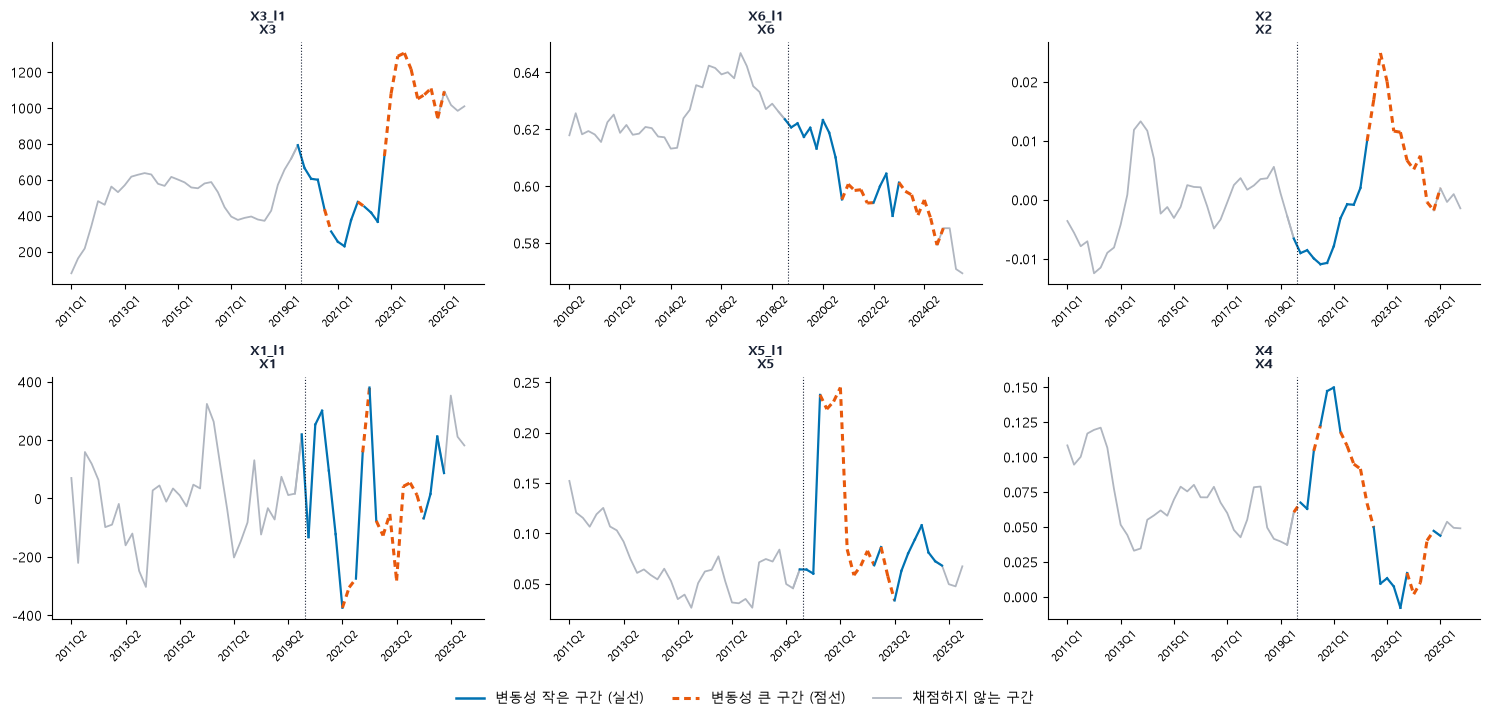

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2))
for ax, v in zip(axes.ravel(), NAMES):
    d_ = raw[["quarter", v]].dropna().reset_index(drop=True)
    y, qs = d_[v].values.astype(float), d_["quarter"].values
    origins = sorted(raw_all(v)["origin"].unique())
    o0, o1 = origins[0], origins[-1]
    k = np.arange(len(y))
    ax.plot(k[:o0], y[:o0], color="#B0B6C0", linewidth=1.3)                          # 채점 이전
    ax.plot(k[o1 - 1:], y[o1 - 1:], color="#B0B6C0", linewidth=1.3)                  # 마지막 4분기(예측 대상만)
    for o in origins:                                                                # origin o는 분기 o-1까지가 훈련 데이터
        i = o - 1
        if o == o0:
            ax.plot(k[i - 1:i + 1], y[i - 1:i + 1], color="#B0B6C0", linewidth=1.3)
        hi_ = o in SEG[v]
        ax.plot(k[i:i + 2], y[i:i + 2], color="#E8590C" if hi_ else "#0072B2", linewidth=2.2 if hi_ else 1.6, linestyle=(0, (2.2, 1.6)) if hi_ else "-")
    ax.axvline(o0 - 0.5, color="#172033", linestyle=":", linewidth=0.8)
    ax.set_xticks(k[::8])
    ax.set_xticklabels(qs[::8], rotation=45, fontsize=8)
    ax.set_title(f"{v}\n{NAMES[v]}", fontsize=9.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([0], [0], color="#0072B2", linewidth=1.8, label="변동성 작은 구간 (실선)"),
                    Line2D([0], [0], color="#E8590C", linewidth=2.2, linestyle=(0, (2.2, 1.6)), label="변동성 큰 구간 (점선)"),
                    Line2D([0], [0], color="#B0B6C0", linewidth=1.3, label="채점하지 않는 구간")], loc="lower center", ncol=3, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 결론

- **선정 모델**: 변수마다 다르다. X3_l1은 GARCH, X6_l1은 SV, X2는 AR단독, X1_l1, X5_l1, X4는 GARCH다. 리샘플링 구간과 자체 구간이 각각 3개다.
- **d는 12-1 판정과 맞다**: d=1로 판정한 X3_l1, X6_l1은 d=1이, d=0으로 판정한 X2, X1_l1은 d=0이 선정된다. 애매했던 X5_l1, X4는 모두 d=0이 나았다.
- **계절성은 거의 없다**: 6개 변수 모두 계절 단위근 검정(OCSB, CH)이 계절 차분 불필요(0)이고 분기 평균 차이도 없다(F 검정 p 0.18 이상). 4분기 합, 전년 대비 증가율, 비중이라 계절 패턴이 이미 상쇄되어 있기 때문으로 본다. X4는 ACF 시차 4가 0.303으로 유의 한계(0.253)를 조금 넘지만 나머지 세 테스트는 계절성이 없다고 본다.
- **D=1은 대부분 CRPS를 나쁘게 한다**(주요 기준 테스트): 5개 변수에서 D=1의 최저 CRPS가 D=0보다 30~40% 높다. 예외는 X6_l1로 4% 낮아지지만 계절성 신호는 없고(ACF 0.183, F 검정 p 0.178, nsdiffs 0), 이득은 시차 4 차분이 추세를 부드럽게 하는 효과로 보인다.
- **수치 테스트와 주요 기준 테스트의 비교(5절)**: 6개 모두 D=0으로 일치한다(계절성 신호 없음). 선정 규칙을 '커버리지 최대'에서 '90%에 가장 가까운 것'으로 바꾸기 전에는 X6_l1만 D=1이 선정됐다(커버리지 92%).

## 한계

- **d를 전체 데이터로 정했다**: d=1 변수(X3_l1, X6_l1)는 그 시점 데이터만으로는 d=1이 거의 나오지 않아 백테스트에 낙관 편향이 있을 수 있다(12-1 5절).
- **평균식이 AR로 제한된다**: GARCH와 SV가 AR만 지원해 MA 항을 쓰지 않았다(`max_Q=0`). 4분기 합이나 전년 대비 증가율은 구성상 MA 구조가 생길 수 있어 AR 제한이 결과에 영향을 줬을 수 있다.
- **표본이 작아 검정력이 낮다**: 관측 59~63개라 단위근, 계절성 검정이 약하다. '계절성 없음'은 '있다는 증거가 없음'이다.
- **로그 스케일의 점예측은 중앙값이다**: `exp(μ)`는 기댓값(`exp(μ + σ²/2)`)보다 낮다. 구간과 CRPS에는 영향이 없고, 로그가 선정된 변수는 X5_l1 하나다. smearing 보정을 X3_l1(12-14)과 X5_l1(12-15)에서 시험했으나 선정된 구조에서 MSE가 오히려 11~85% 나빠져 도입하지 않았다. 점예측을 기댓값으로 써야 하면 별도로 검토한다.
- **변동성이 큰 구간만 보면 선정이 흔들린다**: 변동성 큰 구간(변수마다 origin 10~12개)만으로 다시 선정하면 6개 중 4개(X3, X6, X1, X4)의 선정 조합이 바뀐다(6절). 다만 (d, D)는 X4(d=0에서 d=1로)을 빼고 같고, 나머지는 모델이나 구간 종류가 바뀌는 정도다. origin이 10~12개뿐이라 선정이 불안정하다.
- **선정이 채점 구간 전체의 결과로 이뤄졌고 발표 시차와 데이터 수정은 반영하지 않았다**: 모델 계산은 각 시점 이전 데이터만 쓰고 단위 상수도 훈련 구간 기준이지만(12-0), 최적 구조는 채점 구간 전체의 점수로 골랐고 변수별 발표 시차와 사후 수정은 반영하지 않아 점수가 낙관적일 수 있다.
- **리샘플링 구간은 난수 시드에 따라 점수가 조금 달라진다**: 시드를 42로 통일해 계산했고, 시드 5개로 보면 6개 중 5개는 선정이 같지만 X1는 GARCH와 SV가 사실상 동점이라 시드에 따라 선정이 갈린다(14-5). 자체 구간 변수(X2, X5, X6)는 난수를 쓰지 않아 영향이 없다.
